In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("COVID19_RQ3_MapReduce") \
    .getOrCreate()

sc = spark.sparkContext


In [3]:
data_path = "../../covid.csv"
df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(data_path)
)

print("Number of records:", df.count())
df.printSchema()


Number of records: 10647
root
 |-- dateRep: string (nullable = true)
 |-- year_week: string (nullable = true)
 |-- cases_weekly: integer (nullable = true)
 |-- deaths_weekly: integer (nullable = true)
 |-- countriesAndTerritories: string (nullable = true)
 |-- geoId: string (nullable = true)
 |-- countryterritoryCode: string (nullable = true)
 |-- popData2019: integer (nullable = true)
 |-- continentExp: string (nullable = true)
 |-- rate_14d: double (nullable = true)



In [4]:
def mapper3(row):

    country = row["countriesAndTerritories"]
    cases = row["cases_weekly"]
    deaths = row["deaths_weekly"]

    if country is None or cases is None or deaths is None:
        return None

    return (
        country,
        (float(cases), float(deaths))
    )

In [5]:
def reducer3(a, b):

    total_cases = a[0] + b[0]
    total_deaths = a[1] + b[1]

    return (
        total_cases,
        total_deaths
    )


In [12]:
import time

start_time = time.time()

mapped = (
    df.select(
        "countriesAndTerritories",
        "cases_weekly",
        "deaths_weekly"
    )
    .rdd
    .map(mapper3)
    .filter(lambda x: x is not None)
)

reduced = mapped.reduceByKey(reducer3)

results = reduced.map(
    lambda x: (
        x[0],
        x[1][0],
        x[1][1],
        None if x[1][0] == 0
        else (x[1][1] / x[1][0]) * 100
    )
).collect()

end_time = time.time()

execution_time = end_time - start_time

print("MapReduce execution time: {:.4f} seconds".format(execution_time))


MapReduce execution time: 0.4799 seconds


In [7]:
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DoubleType
)

schema = StructType([
    StructField("country", StringType(), False),
    StructField("total_cases", DoubleType(), False),
    StructField("total_deaths", DoubleType(), False),
    StructField("deaths_to_cases_ratio", DoubleType(), True)
])

final_df = spark.createDataFrame(results, schema)

final_df = final_df.orderBy("country")

final_df.show(10, truncate=False)


+-------------------+-----------+------------+---------------------+
|country            |total_cases|total_deaths|deaths_to_cases_ratio|
+-------------------+-----------+------------+---------------------+
|Afghanistan        |55359.0    |2413.0      |4.358821510504163    |
|Albania            |85336.0    |1460.0      |1.71088403487391     |
|Algeria            |109088.0   |2914.0      |2.6712378996773247   |
|Andorra            |10251.0    |106.0       |1.0340454589796118   |
|Angola             |20086.0    |475.0       |2.3648312257293638   |
|Anguilla           |17.0       |0.0         |0.0                  |
|Antigua_and_Barbuda|316.0      |7.0         |2.2151898734177213   |
|Argentina          |1985501.0  |49398.0     |2.487936294164546    |
|Armenia            |168177.0   |3123.0      |1.8569721186606967   |
|Aruba              |7238.0     |64.0        |0.8842221608179055   |
+-------------------+-----------+------------+---------------------+
only showing top 10 rows



In [9]:
# First five countries
first_five = (final_df.orderBy("country").limit(5).collect())
for row in first_five:
    print(
        "{}\t{}\t{}\t{}".format(row["country"],row["total_cases"],row["total_deaths"],row["deaths_to_cases_ratio"])
    )
print()

# Last five countries
last_five = (final_df.orderBy("country", ascending=False).limit(5).collect()[::-1])
for row in last_five:
    print(
        "{}\t{}\t{}\t{}".format(row["country"],row["total_cases"],row["total_deaths"],row["deaths_to_cases_ratio"])
    )


Afghanistan	55359.0	2413.0	4.358821510504163
Albania	85336.0	1460.0	1.71088403487391
Algeria	109088.0	2914.0	2.6712378996773247
Andorra	10251.0	106.0	1.0340454589796118
Angola	20086.0	475.0	2.3648312257293638

Wallis_and_Futuna	9.0	0.0	0.0
Western_Sahara	766.0	1.0	0.13054830287206268
Yemen	2131.0	616.0	28.90661661191929
Zambia	62633.0	853.0	1.3619018728146506
Zimbabwe	34552.0	1326.0	3.83769391062746


+---------------------------+-----------+------------+---------------------+
|country                    |total_cases|total_deaths|deaths_to_cases_ratio|
+---------------------------+-----------+------------+---------------------+
|Laos                       |45.0       |0.0         |0.0                  |
|Vanuatu                    |1.0        |0.0         |0.0                  |
|Marshall_Islands           |4.0        |0.0         |0.0                  |
|Anguilla                   |17.0       |0.0         |0.0                  |
|New_Caledonia              |47.0       |0.0         |0.0                  |
|Cambodia                   |474.0      |0.0         |0.0                  |
|Falkland_Islands_(Malvinas)|48.0       |0.0         |0.0                  |
|Greenland                  |30.0       |0.0         |0.0                  |
|Solomon_Islands            |17.0       |0.0         |0.0                  |
|Saint_Kitts_and_Nevis      |40.0       |0.0         |0.0                  |

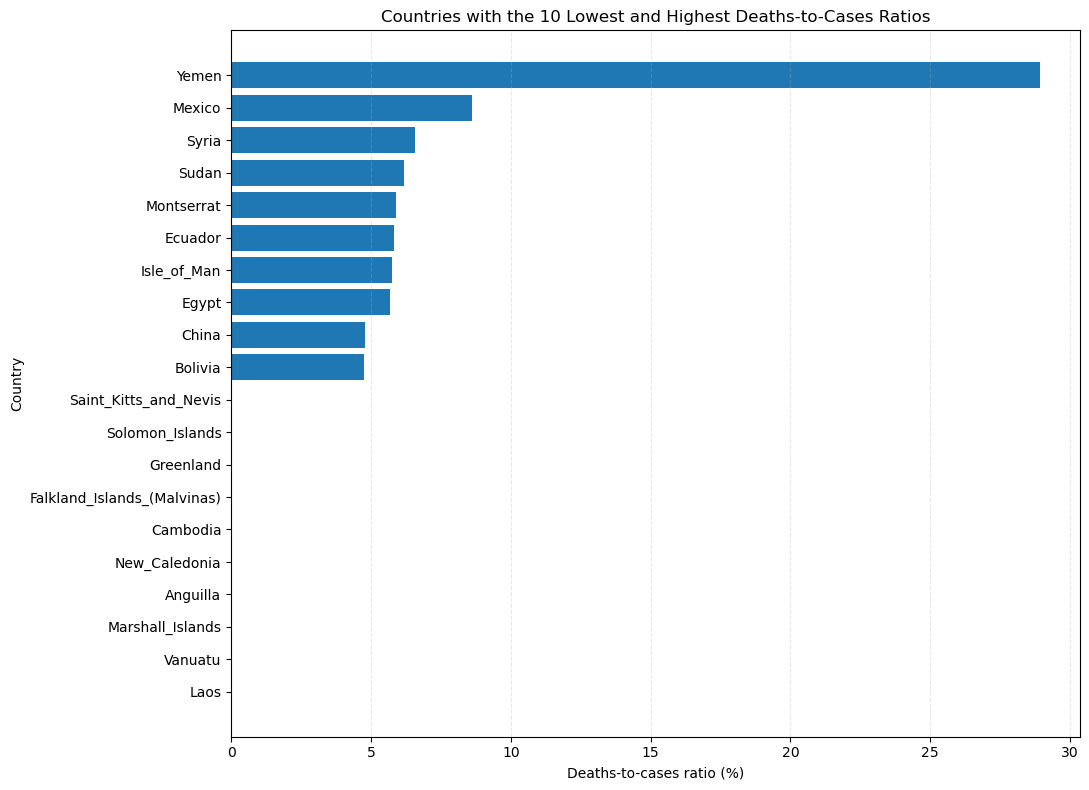

+---------------------------+-----------+------------+---------------------+
|country                    |total_cases|total_deaths|deaths_to_cases_ratio|
+---------------------------+-----------+------------+---------------------+
|Laos                       |45.0       |0.0         |0.0                  |
|Vanuatu                    |1.0        |0.0         |0.0                  |
|Marshall_Islands           |4.0        |0.0         |0.0                  |
|Anguilla                   |17.0       |0.0         |0.0                  |
|New_Caledonia              |47.0       |0.0         |0.0                  |
|Cambodia                   |474.0      |0.0         |0.0                  |
|Falkland_Islands_(Malvinas)|48.0       |0.0         |0.0                  |
|Greenland                  |30.0       |0.0         |0.0                  |
|Solomon_Islands            |17.0       |0.0         |0.0                  |
|Saint_Kitts_and_Nevis      |40.0       |0.0         |0.0                  |

In [15]:
# Figure
from pyspark.sql.functions import col, isnan

valid_ratio_df = final_df.filter(
    col("deaths_to_cases_ratio").isNotNull() &
    ~isnan(col("deaths_to_cases_ratio"))
)

lowest_10 = (
    valid_ratio_df
    .orderBy(col("deaths_to_cases_ratio").asc())
    .limit(10)
)

highest_10 = (
    valid_ratio_df
    .orderBy(col("deaths_to_cases_ratio").desc())
    .limit(10)
)

extreme_countries = (
    lowest_10
    .union(highest_10)
    .orderBy("deaths_to_cases_ratio")
)

extreme_countries.show(20, truncate=False)

import matplotlib.pyplot as plt

plot_data = extreme_countries.select(
    "country",
    "deaths_to_cases_ratio"
).collect()

countries = [row["country"] for row in plot_data]
ratios = [row["deaths_to_cases_ratio"] for row in plot_data]

plt.figure(figsize=(11, 8))

plt.barh(countries, ratios)

plt.title("Countries with the 10 Lowest and Highest Deaths-to-Cases Ratios")
plt.xlabel("Deaths-to-cases ratio (%)")
plt.ylabel("Country")

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


extreme_countries.select(
    "country",
    "total_cases",
    "total_deaths",
    "deaths_to_cases_ratio"
).show(20, truncate=False)
